# Analyze context identification models
The purpose of this notebook is to analyze the learned representations of models trained on the context identification task.

## Imports

In [1]:
import json
import pickle
from pathlib import Path

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

In [2]:
OUT_DIR = Path("../data/context_identification_models")

In [3]:
params_path = OUT_DIR / "context_id_feature_gamma0.0_softmax_seed0_params.pkl"
with open(params_path, "rb") as f:
    params_attn = pickle.load(f)   # dict with W_q, W_k, W_v (JAX arrays / numpy)

In [4]:
history_path = OUT_DIR / "context_id_feature_gamma0.0_softmax_seed0_history.json"
with open(history_path, "r") as f:
    history = json.load(f)

## Plot training dynamics

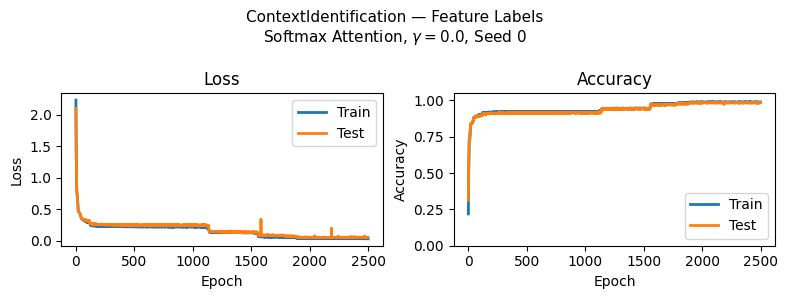

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)

# ---- Loss panel ----
axes[0].plot(history["train_loss"], label="Train", linewidth=2)
axes[0].plot(history["test_loss"], label="Test", linewidth=2)
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# ---- Accuracy panel ----
axes[1].plot(history["train_acc"], label="Train", linewidth=2)
axes[1].plot(history["test_acc"], label="Test", linewidth=2)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()

plt.suptitle(
    "ContextIdentification — Feature Labels\n"
    r"Softmax Attention, $\gamma=0.0$, Seed 0",
    fontsize=11,
)
plt.tight_layout()
plt.show()

## Load weight matrices

In [6]:
Wq = np.array(params_attn["W_q"])  # (D_in, D_attn)
Wk = np.array(params_attn["W_k"])  # (D_in, D_attn)
# Wv exists too, but you asked for Q, K, and QK scores
print("W_q shape:", Wq.shape, "W_k shape:", Wk.shape)

W_q shape: (10, 10) W_k shape: (10, 10)


## Visualize query and key matrices

In [7]:
D_in, D_attn = Wq.shape
L = D_in  # by your design, L == D_in

X = np.eye(L, dtype=np.float32)[None, :, :]   # (B=1, L, D_in)

Q = X @ Wq   # (1, L, D_attn)
K = X @ Wk   # (1, L, D_attn)

# Pre-softmax scores = Q K^T / sqrt(D_attn)
scores = (Q @ np.transpose(K, (0, 2, 1))) / np.sqrt(D_attn)  # (1, L, L)

Q0 = Q[0]         # (L, D_attn)
K0 = K[0]         # (L, D_attn)
S0 = scores[0]    # (L, L)

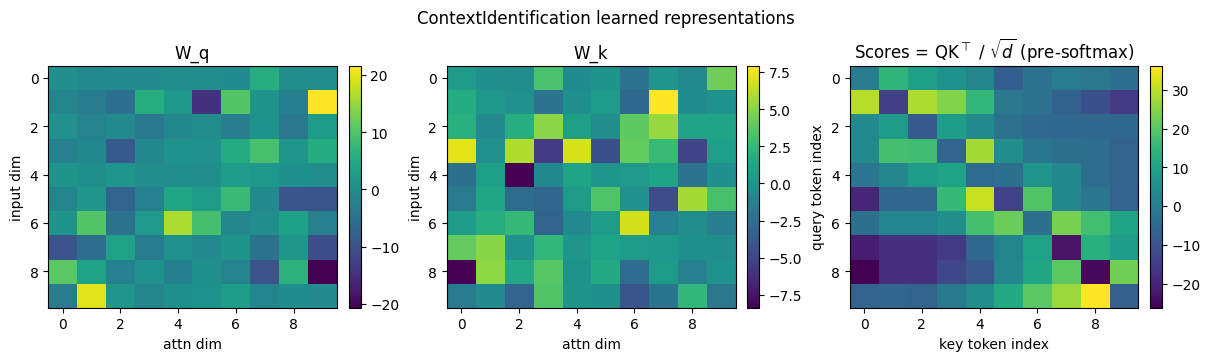

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)

im0 = axes[0].imshow(Wq, aspect="auto")
axes[0].set_title("W_q")
axes[0].set_xlabel("attn dim")
axes[0].set_ylabel("input dim")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(Wk, aspect="auto")
axes[1].set_title("W_k")
axes[1].set_xlabel("attn dim")
axes[1].set_ylabel("input dim")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(S0, aspect="auto")
axes[2].set_title(r"Scores = QK$^\top$ / $\sqrt{d}$ (pre-softmax)")
axes[2].set_xlabel("key token index")
axes[2].set_ylabel("query token index")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(f"ContextIdentification learned representations", fontsize=12)
plt.show()

## Visualize value matrices

In [9]:
Wv = np.array(params_attn["W_v"])

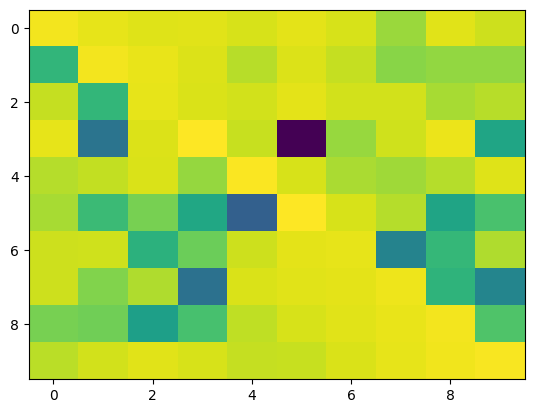

In [10]:
plt.imshow(Wv, aspect="auto")